# **C14 - Black Scholes para valuar activos**
## **Simulación de Procesos Financieros**

---

**Autor:** Francisco Uriel Ledezma Chávez  
**Carrera:** Ingeniería Financiera  
**Institución:** ITESO — Universidad Jesuita de Guadalajara  
**Semestre:** 5° — Simulación de Procesos Financieros  
**Fecha de realización:** 21 de octubre de 2026

---

**Ejercicio:** descargar los precios de cierre de AAPL, MSFT, NVDA, META y AMZN, estimar su rendimiento y su volatilidad con los datos de 2025, simular el precio con el movimiento browniano geométrico que subyace a Black-Scholes y contrastar las trayectorias simuladas, junto con sus antitéticas, contra los precios observados durante el primer semestre de 2026.

C13 mostró que una extracción $Z$ y su opuesta $-Z$ forman un par que reduce la varianza del precio de una call, aunque la ganancia quedó acotada por el piso en cero del pago, mientras que aquí la misma técnica se aplica a la variable más simple posible, el precio del activo, que responde a $Z$ de forma casi lineal, y el ejercicio añade además la prueba más exigente para cualquier modelo, que es enfrentarlo con un periodo que no vio al estimar sus parámetros.

## Índice de contenidos

1. Sección 1 — Datos de entrenamiento y de prueba
2. Sección 2 — Rendimiento, volatilidad y deriva de cada periodo
3. Sección 3 — Proyección del segundo semestre de 2026
4. Sección 4 — Trayectorias antitéticas frente al precio observado
5. Sección 5 — Valor esperado del precio con pares antitéticos
6. Sección 6 — Ubicación del precio real en la distribución simulada
7. Sección 7 — Conclusiones

## Importación de bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import yfinance as yf

np.random.seed(21)

## 1. Datos de entrenamiento y de prueba

Los datos se separan en dos periodos que no se traslapan, el año 2025 completo, que sirve para estimar los parámetros, y el primer semestre de 2026, que se reserva como prueba y contra el cual se juzgan las simulaciones, de modo que ninguna cifra del periodo de prueba influye en el modelo que pretende anticiparlo.

In [2]:
tickers = ['AAPL', 'MSFT', 'NVDA', 'META', 'AMZN']
Start_date = '2025-01-01'
End_date = '2026-01-01'

Prices = yf.download(tickers, start=Start_date, end=End_date, progress=False)['Close']
Prices_Test = yf.download(tickers, start='2026-01-01', end='2026-07-01', progress=False)['Close']
print("Entrenamiento:", Prices.index[0].date(), "a", Prices.index[-1].date(), "·", len(Prices), "cierres")
print("Prueba:       ", Prices_Test.index[0].date(), "a", Prices_Test.index[-1].date(), "·", len(Prices_Test), "cierres")
Prices_Test

Entrenamiento: 2025-01-02 a 2025-12-31 · 250 cierres
Prueba:        2026-01-02 a 2026-06-30 · 123 cierres


Ticker,AAPL,AMZN,META,MSFT,NVDA
Date,,,,,
2026-01-02,270.274353,226.500000,648.739868,469.958496,188.409134
2026-01-05,266.534546,233.059998,657.098267,469.869110,187.680832
2026-01-06,261.647766,240.929993,658.923706,475.493408,186.802887
2026-01-07,259.623322,241.559998,647.024353,480.422119,188.668518
2026-01-08,258.336853,246.289993,644.401062,475.095886,184.608017
...,...,...,...,...,...
2026-06-24,292.827423,234.270004,557.230225,364.773315,198.777573
2026-06-25,274.912903,227.009995,542.441895,352.167023,195.521225
2026-06-26,283.535461,232.690002,549.816101,372.269196,192.314804


El entrenamiento reúne 250 cierres a lo largo de 2025 y la prueba 123 cierres entre enero y junio de 2026, semestre en el cual los cinco activos siguieron caminos muy distintos, ya que AAPL pasó de 270.27 a 289.11 y NVDA de 188.41 a 199.87, mientras que MSFT cayó de 469.96 a 372.32 y META de 648.74 a 562.85.

## 2. Rendimiento, volatilidad y deriva de cada periodo

Cada periodo se resume en dos cifras anualizadas, la media de los rendimientos logarítmicos diarios multiplicada por 252 y su desviación estándar multiplicada por $\sqrt{252}$, aunque la primera no puede entregarse directamente al generador, ya que la media logarítmica estima $\mu - \sigma^2/2$ y `create_paths` vuelve a restar $\sigma^2/2$ dentro del exponente, de modo que la deriva que recibe el movimiento browniano geométrico se recupera sumándole la mitad de la varianza.

$$\hat{m} = 252\;\overline{\ln\left(S_t/S_{t-1}\right)}, \qquad \hat{\sigma} = \sqrt{252}\;s_{\ln}, \qquad \hat{\mu} = \hat{m} + \frac{\hat{\sigma}^2}{2}$$

In [3]:
Rendimientos_Logaritmicos = np.log((Prices) / (Prices.shift(1))).dropna()
Rendimiento_Esperado = Rendimientos_Logaritmicos.mean() * 252
Volatilidad = Rendimientos_Logaritmicos.std() * np.sqrt(252)
Deriva = Rendimiento_Esperado + 0.5 * Volatilidad ** 2   # deriva aritmética que recibe el GBM

pd.DataFrame({
    "Rendimiento logarítmico anual": Rendimiento_Esperado,
    "Volatilidad anual": Volatilidad,
    "Deriva del GBM": Deriva,
}).round(4)

,Rendimiento logarítmico anual,Volatilidad anual,Deriva del GBM
Ticker,,,
AAPL,0.1146,0.3216,0.1663
AMZN,0.0476,0.3433,0.1065
META,0.1011,0.3779,0.1725
MSFT,0.1536,0.2407,0.1826
NVDA,0.3028,0.4984,0.4270


In [4]:
Rendimientos_Logaritmicos_Test = np.log((Prices_Test) / (Prices_Test.shift(1))).dropna()
Rendimiento_Esperado_Test = Rendimientos_Logaritmicos_Test.mean() * 252
Volatilidad_Test = Rendimientos_Logaritmicos_Test.std() * np.sqrt(252)
Deriva_Test = Rendimiento_Esperado_Test + 0.5 * Volatilidad_Test ** 2

pd.DataFrame({
    "Rendimiento logarítmico anual": Rendimiento_Esperado_Test,
    "Volatilidad anual": Volatilidad_Test,
    "Deriva del GBM": Deriva_Test,
    "Cambio de rendimiento frente a 2025": Rendimiento_Esperado_Test - Rendimiento_Esperado,
}).round(4)

,Rendimiento logarítmico anual,Volatilidad anual,Deriva del GBM,Cambio de rendimiento frente a 2025
Ticker,,,,
AAPL,0.1392,0.2618,0.1734,0.0246
AMZN,0.1052,0.3185,0.1560,0.0577
META,-0.2934,0.4026,-0.2123,-0.3944
MSFT,-0.4811,0.3439,-0.4219,-0.6347
NVDA,0.1219,0.3828,0.1952,-0.1809


En 2025 los cinco activos tuvieron rendimiento logarítmico positivo, de 0.0476 en AMZN a 0.3028 en NVDA, y la corrección de la deriva pesa más donde la volatilidad es mayor, ya que con 0.4984 de volatilidad NVDA pasa de 0.3028 a 0.4270, mientras que MSFT, con la volatilidad más baja de 0.2407, apenas pasa de 0.1536 a 0.1826, diferencia que sin la corrección habría desplazado hacia abajo la mediana de cada simulación.

El primer semestre de 2026 rompió ese patrón en tres de los cinco activos, pues el rendimiento logarítmico anualizado de MSFT pasó de 0.1536 a −0.4811, un cambio de −0.6347, el de META de 0.1011 a −0.2934 y el de NVDA de 0.3028 a 0.1219, mientras que AAPL y AMZN mejoraron ligeramente, y como la volatilidad de MSFT subió además de 0.2407 a 0.3439, el periodo de prueba no es una continuación del de entrenamiento sino, al menos para MSFT y META, un régimen distinto que ningún modelo calibrado con 2025 podía conocer.

## 3. Proyección del segundo semestre de 2026

La primera simulación proyecta el segundo semestre de 2026 a partir del último cierre de junio, con 50 trayectorias de 126 pasos y los parámetros del propio periodo de prueba, que son los más recientes disponibles, de modo que funciona como un pronóstico hacia adelante y no como una prueba contra datos observados.

In [5]:
def create_paths(S0, r, std, T, n, M):
    """Trayectorias GBM de clase (C09, C10). Forma (M, n+1); la columna 0 es S0."""
    dt = T / n
    paths = np.zeros((M, n + 1))
    paths[:, 0] = S0
    for i in range(1, n + 1):
        Z = np.random.standard_normal(M)
        paths[:, i] = paths[:, i - 1] * np.exp((r - 0.5 * std ** 2) * dt + std * np.sqrt(dt) * Z)
    return paths

AAPL: parte de   289.11 · mediana simulada al cierre   315.88 · rango de las 50 trayectorias   217.11 a   544.04


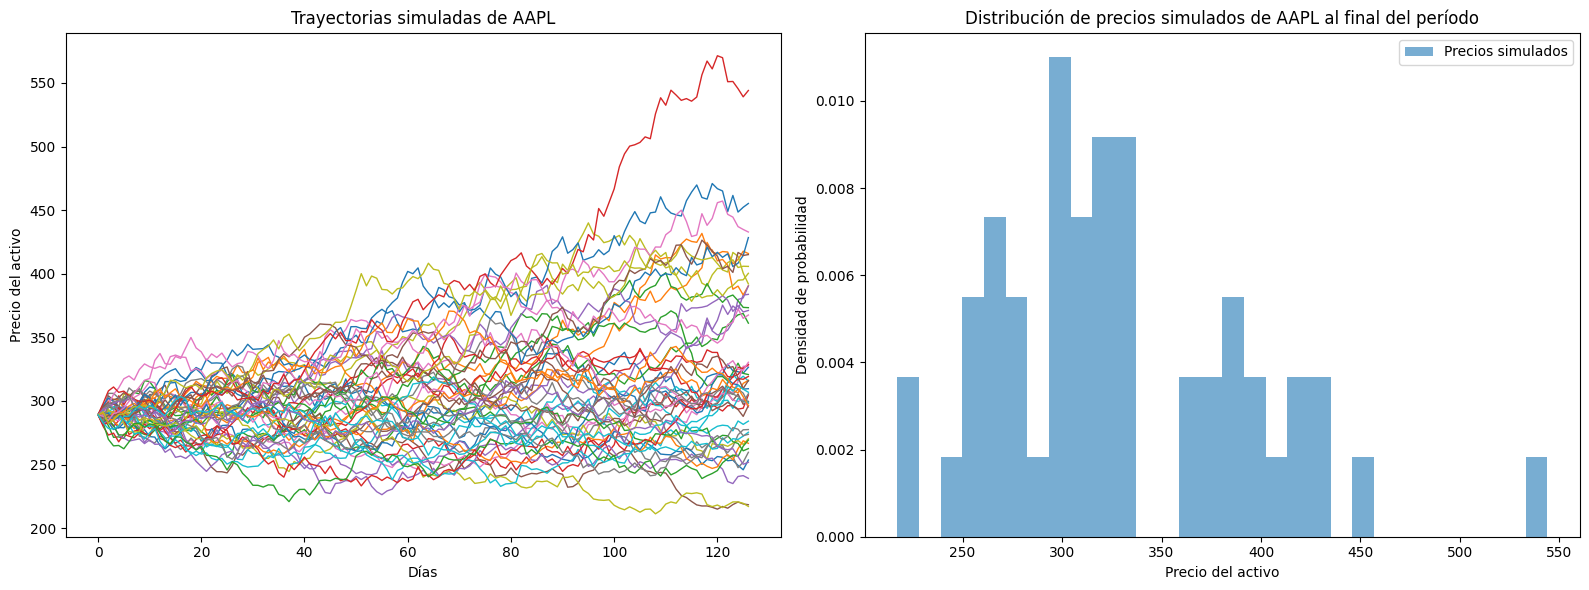

MSFT: parte de   372.32 · mediana simulada al cierre   282.74 · rango de las 50 trayectorias   174.67 a   456.10


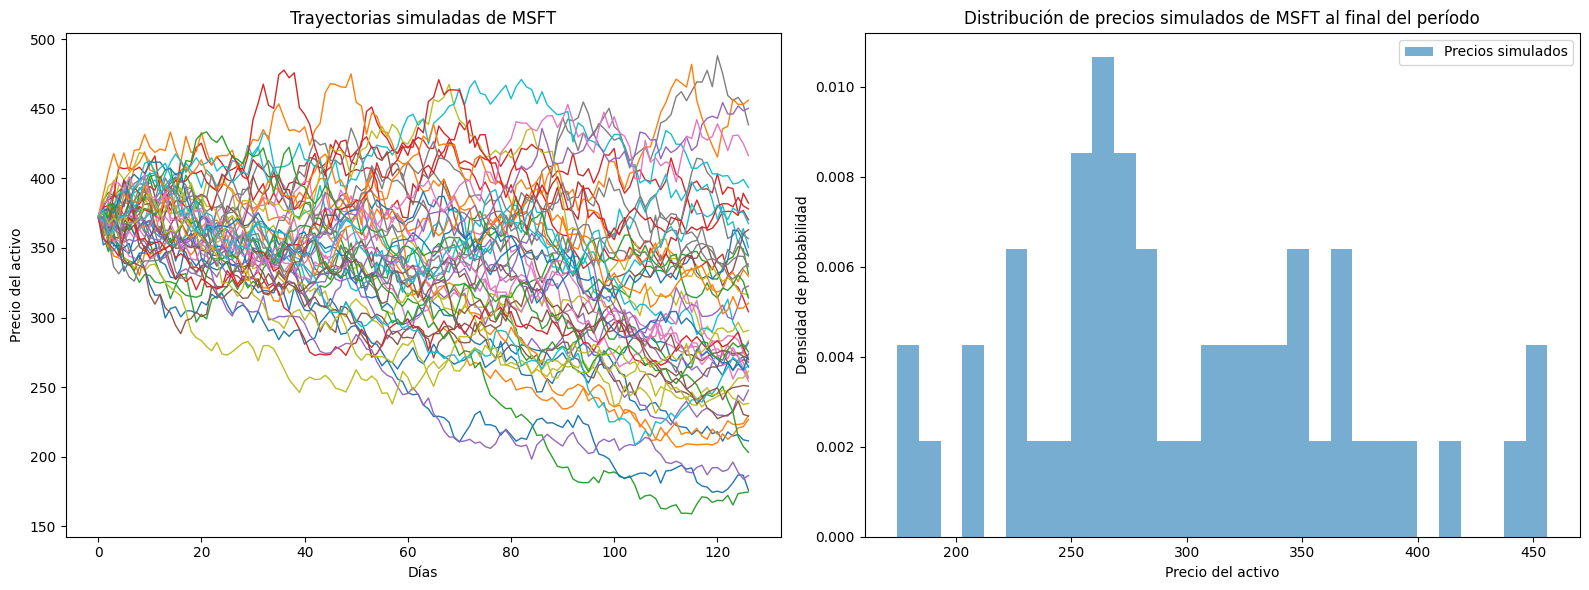

NVDA: parte de   199.87 · mediana simulada al cierre   230.70 · rango de las 50 trayectorias   134.95 a   497.21


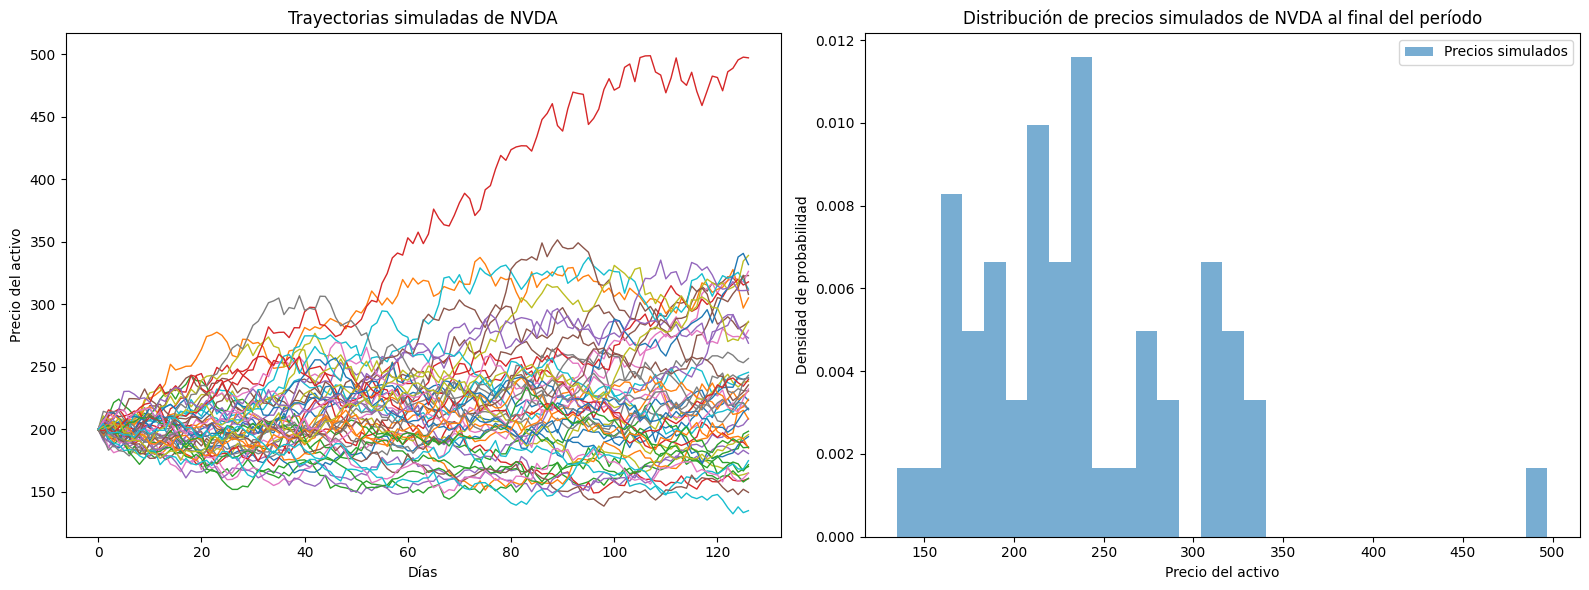

META: parte de   562.85 · mediana simulada al cierre   483.26 · rango de las 50 trayectorias   259.95 a   881.92


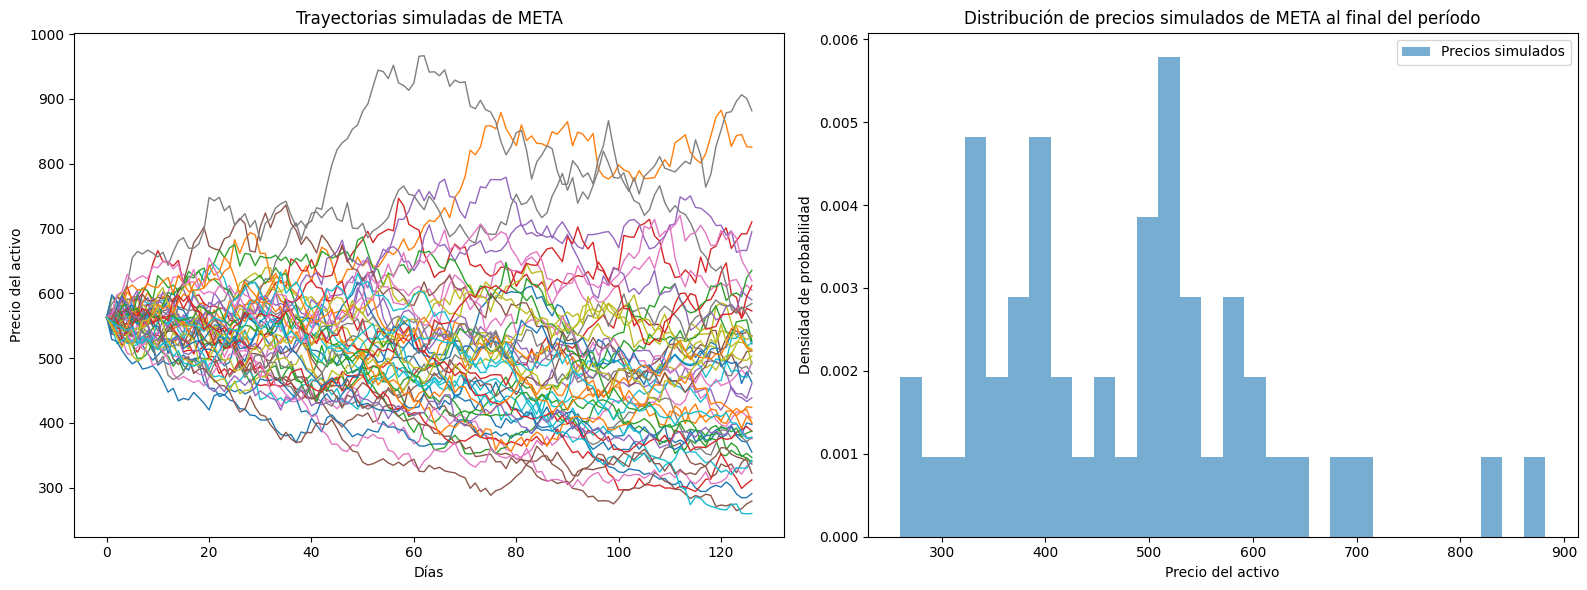

AMZN: parte de   238.34 · mediana simulada al cierre   244.42 · rango de las 50 trayectorias   138.27 a   455.80


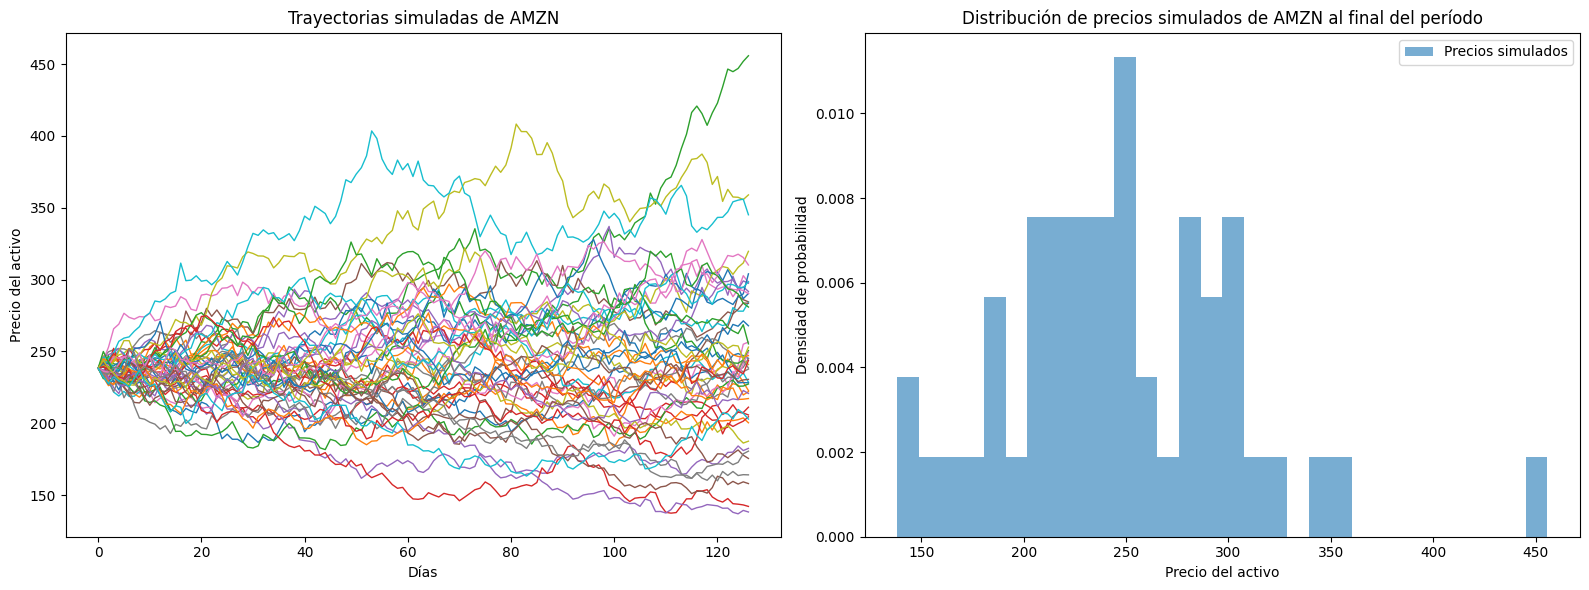

In [6]:
for ticker in tickers:
    S0 = Prices_Test[ticker].iloc[-1]
    r = Deriva_Test[ticker]
    std = Volatilidad_Test[ticker]
    T = 0.5
    n = 126
    M = 50

    paths = create_paths(S0, r, std, T, n, M)
    print(f"{ticker}: parte de {S0:8.2f} · mediana simulada al cierre {np.median(paths[:, -1]):8.2f}"
          f" · rango de las {M} trayectorias {paths[:, -1].min():8.2f} a {paths[:, -1].max():8.2f}")

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].plot(paths.T, lw=1)
    axes[0].set_title(f'Trayectorias simuladas de {ticker}')
    axes[0].set_xlabel('Días')
    axes[0].set_ylabel('Precio del activo')

    axes[1].hist(paths[:, -1], bins=30, density=True, alpha=0.6)
    axes[1].set_title(f'Distribución de precios simulados de {ticker} al final del período')
    axes[1].set_xlabel('Precio del activo')
    axes[1].set_ylabel('Densidad de probabilidad')
    axes[1].legend(['Precios simulados'])

    fig.tight_layout()
    plt.show()

Las proyecciones heredan el régimen del semestre que las alimenta, por lo cual MSFT, que parte de 372.32, tiene una mediana simulada de 282.74 al cierre del año y META, que parte de 562.85, una de 483.26, mientras que AAPL sube de 289.11 a una mediana de 315.88 y AMZN apenas se mueve de 238.34 a 244.42.

La dispersión es tan relevante como la mediana, ya que el rango de las 50 trayectorias de NVDA va de 134.95 a 497.21 y el de META de 259.95 a 881.92, abanicos tan amplios que la mediana resulta poco informativa por sí sola, y además proyectar seis meses con una deriva estimada sobre otros seis supone que una caída como la de MSFT continuará al mismo ritmo, supuesto que la sección 6 obliga a tomar con cautela, pues muestra que un semestre puede cambiar de régimen sin aviso.

## 4. Trayectorias antitéticas frente al precio observado

La segunda simulación es la prueba propiamente dicha, ya que parte del primer cierre de 2026 con los parámetros de 2025 y avanza tantos pasos como días hábiles separan el primer y el último cierre del periodo de prueba, 122, de modo que cada trayectoria termina en la misma fecha que el último precio observado, y cada una se acompaña de su trayectoria antitética, construida con los mismos choques diarios cambiados de signo, mientras que la línea verde promedia día con día los 50 pares y estima así la trayectoria esperada del precio.

In [7]:
def create_antithetic_paths(S0, r, std, T, n, M):
    """Trayectorias Antiteticas de Clase C13."""
    dt = T / n
    paths = np.zeros((M, n + 1))
    anthetic_paths = np.zeros((M, n + 1))
    paths[:, 0] = S0
    anthetic_paths[:, 0] = S0

    for t in range(n):
        z = np.random.normal(0, 1, M)
        drift = (r - 0.5 * std**2) * dt
        diffusion = std * np.sqrt(dt) * z

        paths[:, t + 1] = paths[:, t] * np.exp(drift + diffusion)
        anthetic_paths[:, t + 1] = anthetic_paths[:, t] * np.exp(drift - diffusion)

    return paths, anthetic_paths

def create_antithetic_final_price(S0, r, std, T, M):
    drift = (r - 0.5 * std**2) * T
    diffusion = std * np.sqrt(T)
    z = np.random.normal(0, 1, M)
    Sz = S0 * np.exp(drift + diffusion * z)
    Szneg = S0 * np.exp(drift - diffusion * z)
    return (Sz + Szneg) / 2

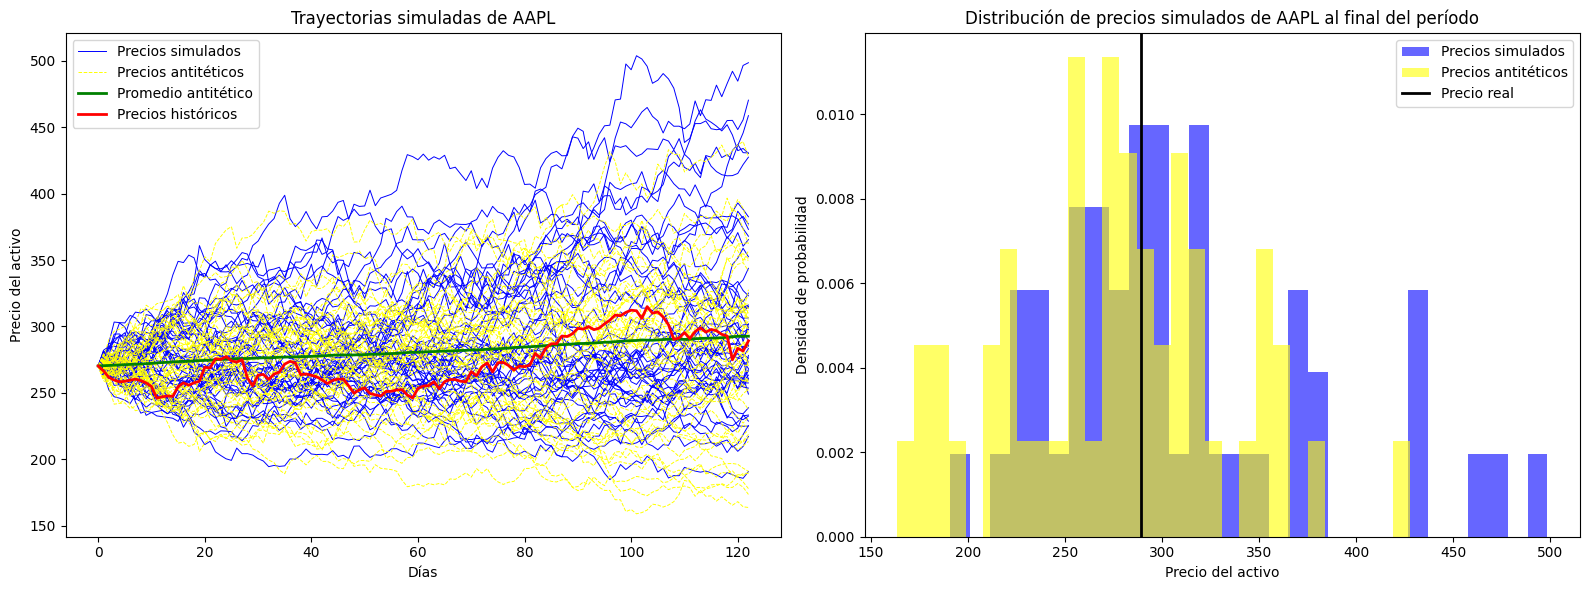

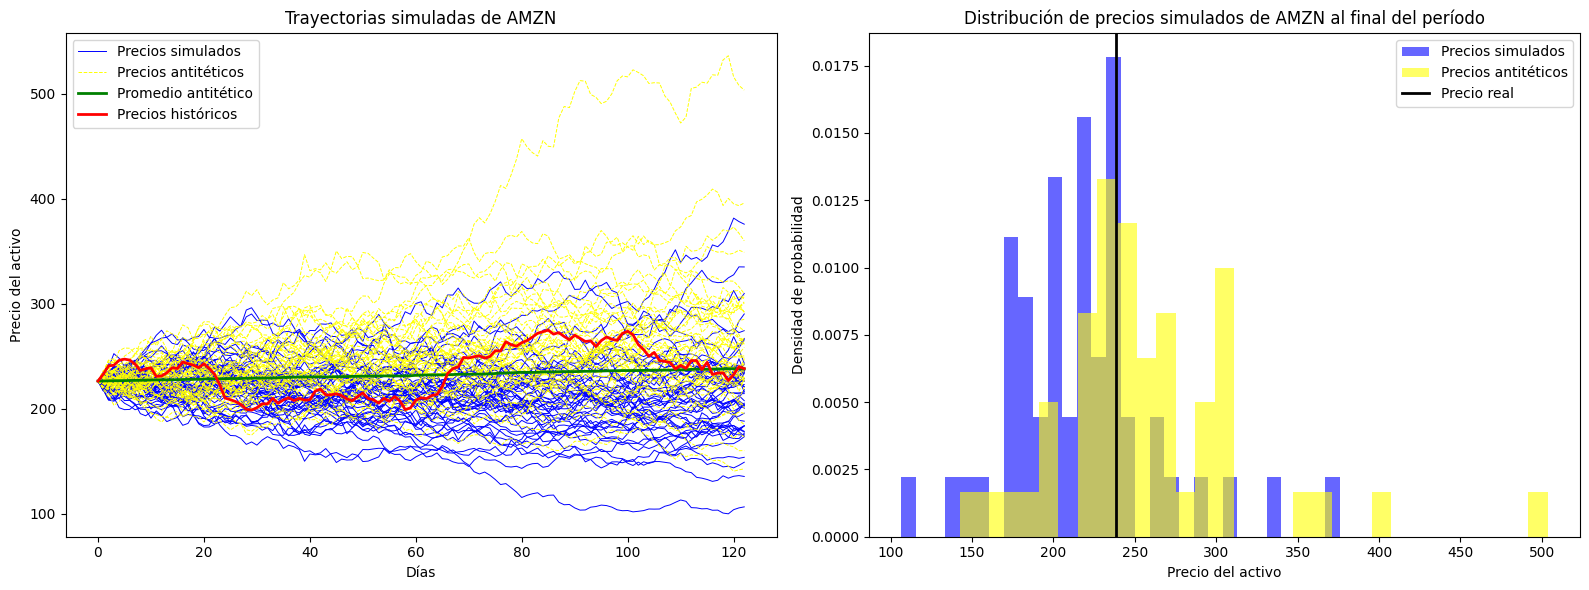

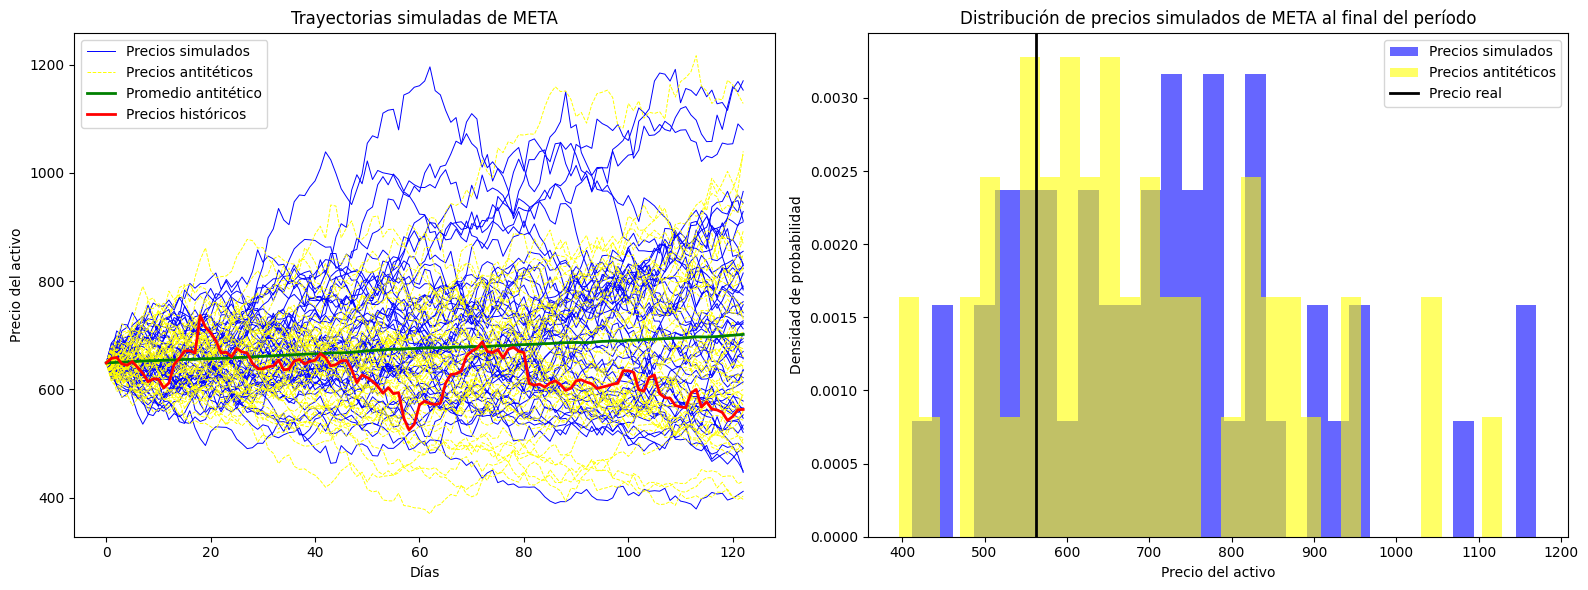

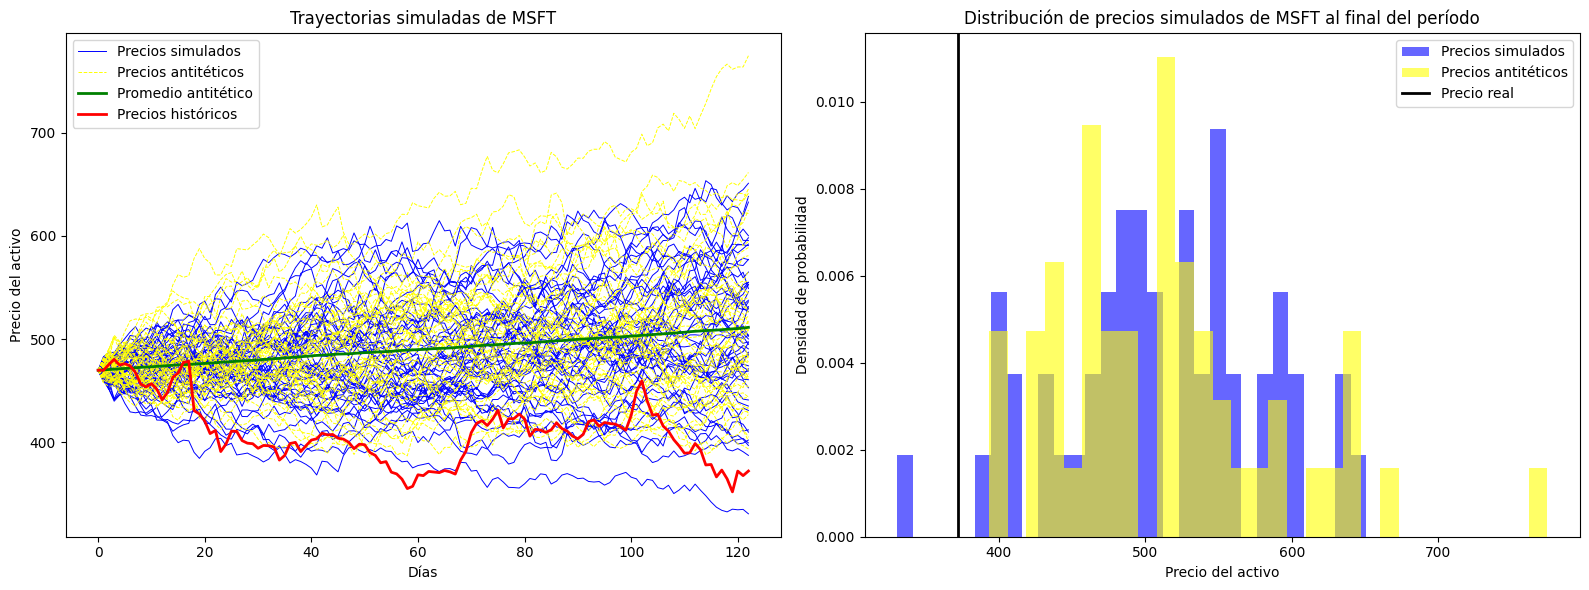

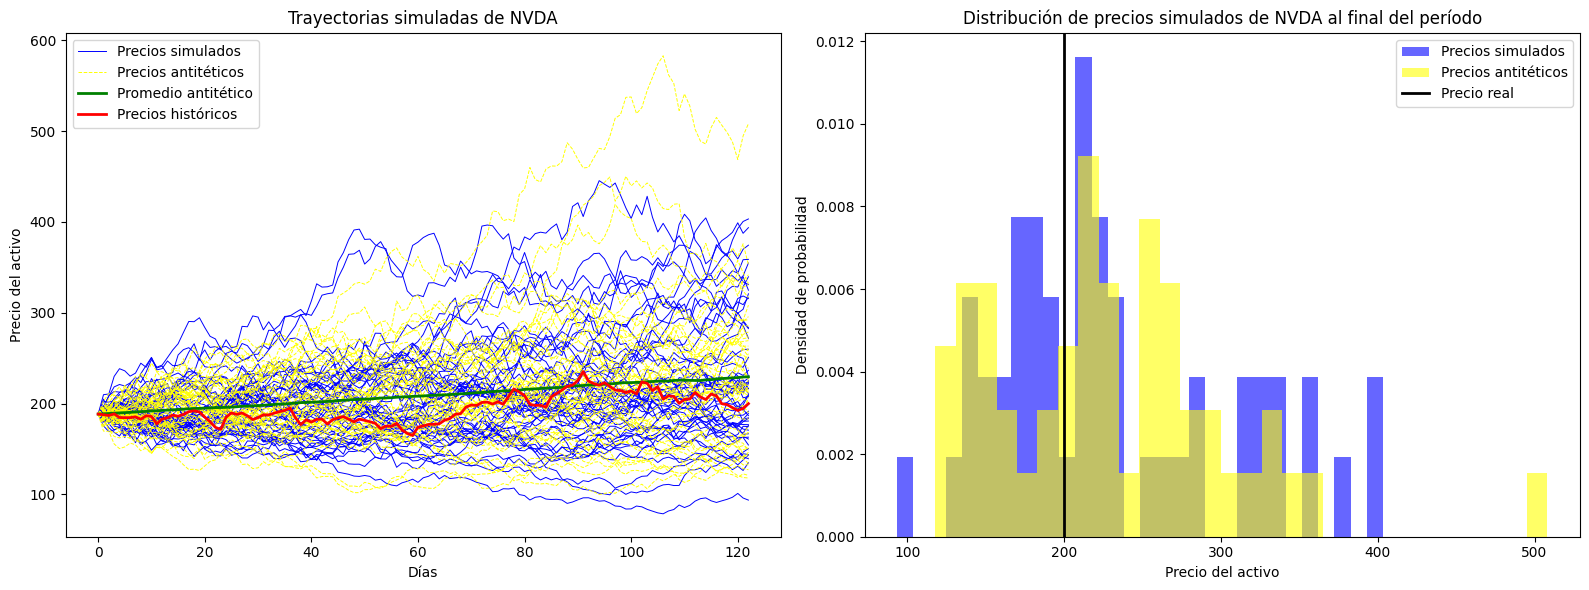

In [8]:
n = len(Prices_Test) - 1   # pasos entre el primer y el último cierre de prueba
T = n / 252
M = 50

for ticker in Prices.columns:
    S0 = Prices_Test[ticker].iloc[0]
    r = Deriva[ticker]
    std = Volatilidad[ticker]

    n_paths, antithetic_paths = create_antithetic_paths(S0, r, std, T, n, M)
    promedio_antitetico = ((n_paths + antithetic_paths) / 2).mean(axis=0)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    lineas_sim = axes[0].plot(n_paths.T, lw=0.7, color='blue')
    lineas_anti = axes[0].plot(antithetic_paths.T, lw=0.7, linestyle='--', color='yellow')
    linea_promedio, = axes[0].plot(promedio_antitetico, lw=2, color='green')
    linea_real, = axes[0].plot(Prices_Test[ticker].values, lw=2, color='red')
    axes[0].set_title(f'Trayectorias simuladas de {ticker}')
    axes[0].set_xlabel('Días')
    axes[0].set_ylabel('Precio del activo')
    axes[0].legend([lineas_sim[0], lineas_anti[0], linea_promedio, linea_real], ['Precios simulados', 'Precios antitéticos', 'Promedio antitético', 'Precios históricos'])

    axes[1].hist(n_paths[:, -1], bins=30, density=True, alpha=0.6, color='blue', label='Precios simulados')
    axes[1].hist(antithetic_paths[:, -1], bins=30, density=True, alpha=0.6, color='yellow', label='Precios antitéticos')
    axes[1].axvline(Prices_Test[ticker].iloc[-1], color='black', linewidth=2, label='Precio real')
    axes[1].set_title(f'Distribución de precios simulados de {ticker} al final del período')
    axes[1].set_xlabel('Precio del activo')
    axes[1].set_ylabel('Densidad de probabilidad')
    axes[1].legend()

    fig.tight_layout()
    plt.show()

Las gráficas muestran que cada trayectoria antitética es el reflejo de su pareja alrededor de la tendencia, de modo que donde una sube la otra baja, y AMZN lo ilustra con claridad, pues sus 50 trayectorias azules terminaron cargadas hacia abajo y las amarillas reflejan ese sesgo hacia arriba, con lo cual el promedio de cada par, la línea verde, resulta una curva casi lisa que crece a la tasa de la deriva, ya que los choques de cada par se cancelan y sólo queda el componente determinista del movimiento.

El precio real se comporta de forma muy distinta según el activo, ya que en AAPL y AMZN la línea roja recorre el centro del abanico y termina casi sobre la línea verde, en NVDA se mantiene ligeramente por debajo de ella, en META se separa hacia la mitad inferior a partir del primer mes, mientras que en MSFT se despega hacia abajo desde las primeras semanas y termina por debajo de casi todos los escenarios simulados.

## 5. Valor esperado del precio con pares antitéticos

El valor esperado del precio terminal bajo el movimiento browniano geométrico tiene forma cerrada, $E[S_T] = S_0 e^{\mu T}$, lo cual permite medir la técnica antitética sobre el propio activo contra una referencia exacta, simulando para cada uno 10,000 pares frente a 20,000 precios independientes, y la teoría anticipa además cuánto debe reducirse la varianza, ya que para un precio lognormal la correlación entre el escenario de $Z$ y el de $-Z$ es exactamente $-e^{-\sigma^2 T}$.

$$\rho = \text{corr}\left(S_T(Z),\ S_T(-Z)\right) = -e^{-\sigma^2 T}, \qquad \frac{\text{Var}_{\text{simple}}}{\text{Var}_{\text{antitética}}} = \frac{1}{1+\rho} = \frac{1}{1 - e^{-\sigma^2 T}}$$

In [9]:
M_grande = 10000
valuacion = {}

for ticker in Prices.columns:
    S0 = Prices_Test[ticker].iloc[0]
    r = Deriva[ticker]
    std = Volatilidad[ticker]

    pares = create_antithetic_final_price(S0, r, std, T, M_grande)
    simples = S0 * np.exp((r - 0.5 * std ** 2) * T + std * np.sqrt(T) * np.random.standard_normal(2 * M_grande))
    ee_pares = pares.std(ddof=1) / np.sqrt(M_grande)
    ee_simples = simples.std(ddof=1) / np.sqrt(2 * M_grande)

    valuacion[ticker] = {
        "Valor esperado teórico": S0 * np.exp(r * T),
        "Monte Carlo simple": simples.mean(),
        "Pares antitéticos": pares.mean(),
        "Error estándar simple": ee_simples,
        "Error estándar antitético": ee_pares,
        "Reducción de varianza": (ee_simples / ee_pares) ** 2,
        "Reducción teórica": 1 / (1 - np.exp(-std ** 2 * T)),
    }

pd.DataFrame(valuacion).T.round(4)

,Valor esperado teórico,Monte Carlo simple,Pares antitéticos,Error estándar simple,Error estándar antitético,Reducción de varianza,Reducción teórica
AAPL,292.9391,292.8966,293.0588,0.4719,0.1051,20.1515,20.4714
AMZN,238.4858,237.9968,238.4228,0.4101,0.0933,19.3249,18.0295
META,705.2392,704.1345,705.4774,1.3299,0.3411,15.2022,14.9664
MSFT,513.3901,513.7258,513.2152,0.6163,0.0985,39.1698,36.1531
NVDA,231.6787,231.0762,231.5599,0.5841,0.1946,9.0046,8.8245


Las tres estimaciones coinciden con el valor teórico en los cinco activos, como en MSFT, donde la forma cerrada da 513.39, Monte Carlo simple 513.73 y los pares antitéticos 513.22, aunque la diferencia está en la precisión, ya que el error estándar antitético resulta entre tres y algo más de seis veces menor que el simple, con reducciones de varianza que van de 9.00 en NVDA a 39.17 en MSFT.

El orden de esas reducciones no es azar, pues sigue exactamente a la volatilidad, desde la más baja de MSFT, de 0.2407, hasta la más alta de NVDA, de 0.4984, y la columna teórica lo anticipa con precisión, con 36.15 para MSFT y 8.82 para NVDA frente a las 39.17 y 9.00 medidas, ya que cuanto menor es $\sigma^2 T$ más se parece el precio a una función lineal de $Z$ y más completa resulta la cancelación entre cada par.

La comparación con C13 es la lectura más útil de la tabla, porque la misma técnica que aquí reduce la varianza entre 9 y 39 veces apenas la redujo 1.887 veces para una call europea, y la diferencia no proviene del método sino del pago, ya que el precio del activo es una función casi lineal de $Z$, mientras que la call se anula en casi la mitad de los escenarios y rompe con ello la simetría que la técnica aprovecha.

## 6. Ubicación del precio real en la distribución simulada

La prueba final consiste en ubicar el precio real del 30 de junio dentro de la distribución que el modelo de 2025 asignaba a esa fecha, simulando 10,000 precios terminales por activo y midiendo qué fracción quedó por debajo del valor observado, de modo que un percentil cercano a 50 indica un resultado típico y uno cercano a 0 o a 100, un evento que el modelo consideraba improbable.

In [10]:
ubicacion = {}

for ticker in Prices.columns:
    S0 = Prices_Test[ticker].iloc[0]
    real = Prices_Test[ticker].iloc[-1]
    r = Deriva[ticker]
    std = Volatilidad[ticker]

    ST = S0 * np.exp((r - 0.5 * std ** 2) * T + std * np.sqrt(T) * np.random.standard_normal(M_grande))
    ubicacion[ticker] = {
        "Precio inicial": S0,
        "Precio real final": real,
        "Mediana simulada": np.median(ST),
        "Percentil 5": np.percentile(ST, 5),
        "Percentil 95": np.percentile(ST, 95),
        "Percentil del precio real": 100 * np.mean(ST <= real),
    }

pd.DataFrame(ubicacion).T.round(2)

,Precio inicial,Precio real final,Mediana simulada,Percentil 5,Percentil 95,Percentil del precio real
AAPL,270.27,289.11,286.13,198.05,409.55,51.94
AMZN,226.50,238.34,231.62,157.06,342.78,54.83
META,648.74,562.85,681.23,442.76,1051.94,23.09
MSFT,469.96,372.32,505.25,383.04,665.20,3.54
NVDA,188.41,199.87,217.55,121.63,386.50,40.08


AAPL y AMZN terminaron prácticamente en el centro de su distribución, en los percentiles 51.94 y 54.83, y NVDA en el 40.08, de modo que para tres de los cinco activos el modelo calibrado con 2025 describió bien la incertidumbre del semestre aunque ninguno de ellos repitiera su rendimiento del año anterior.

META quedó en el percentil 23.09, una caída desfavorable pero todavía dentro de lo que el modelo consideraba común, mientras que MSFT terminó en el percentil 3.54, con un precio real de 372.32 por debajo incluso del percentil 5 de 383.04, lo cual significa que el modelo asignaba menos de cuatro probabilidades en cien a un resultado igual o peor que el observado.

Ese resultado no invalida el modelo, ya que entre cinco activos es esperable que alguno caiga en una cola, aunque sí muestra su límite principal, pues la distribución simulada sólo contiene la volatilidad y la deriva de 2025, y cuando la deriva de MSFT pasó de 0.1536 a −0.4811 el modelo no tenía forma de anticiparlo, de modo que el riesgo de un cambio de régimen queda fuera de la incertidumbre que la simulación representa.

## 7. Conclusiones

El ejercicio confirma que el movimiento browniano geométrico calibrado con un año de datos describe razonablemente la incertidumbre de los seis meses siguientes para la mayoría de los activos, ya que AAPL, AMZN y NVDA terminaron el semestre entre los percentiles 40.08 y 54.83 de su distribución simulada y META en el 23.09, mientras que MSFT, con el 3.54, fue el único resultado que el modelo consideraba improbable.

La explicación de ese caso está en los parámetros y no en la simulación, pues el rendimiento logarítmico anualizado de MSFT pasó de 0.1536 en 2025 a −0.4811 en el primer semestre de 2026, y un modelo que supone deriva y volatilidad constantes no puede asignar probabilidad a un cambio de régimen que no está en sus datos, de modo que la cola en la que cayó MSFT mide tanto la mala suerte del semestre como el supuesto de estacionariedad.

La técnica antitética funcionó mucho mejor aquí que en C13, con reducciones de varianza de entre 9.00 y 39.17 frente a 1.887 en la call europea, y la forma cerrada $1/(1 - e^{-\sigma^2 T})$ anticipó esas cifras activo por activo, lo cual confirma que el beneficio del método depende de qué tan lineal sea la variable simulada frente a $Z$ y es máximo cuando la volatilidad es baja.

El ejercicio deja además una corrección metodológica que conviene conservar, ya que la media de los rendimientos logarítmicos estima $\mu - \sigma^2/2$ y no la deriva que recibe el generador, por lo cual entregarla sin sumar la mitad de la varianza resta dos veces el mismo término y desplaza hacia abajo todas las trayectorias, error que en NVDA habría reducido la deriva de 0.4270 a 0.3028.

El análisis tiene dos límites que conviene declarar, ya que la prueba descansa en un solo semestre y en cinco activos, demasiado poco para afirmar que el modelo esté bien calibrado en general, y además el precio de cierre que entrega la descarga se ajusta retroactivamente por dividendos, de modo que las cifras pueden moverse en las últimas decimales entre una ejecución y otra, por lo cual la extensión natural es repetir la prueba sobre varios semestres consecutivos y contar con qué frecuencia el precio real cae fuera del intervalo entre los percentiles 5 y 95.